# LAB EXPERIMENT 03: MULTIPLE LINEAR REGRESSION

## 1. Problem Statement
Given a clean real-estate dataset with continuous predictors (X) and a continuous target `House_Price` (Y):
1. **Formulate** a multivariate linear hypothesis relating property attributes to market value.
2. **Evaluate** the model on an 80:20 train-test split using **MAE, MSE, RMSE, R²** (and adjusted R²).
3. **Analyse residuals and assumptions** - linearity, homoscedasticity, normality and no severe multicollinearity.

## 2. Mathematical formulation
$$Y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \dots + \beta_p X_p + \varepsilon,\qquad \varepsilon \sim N(0,\sigma^2)$$
OLS closed form (normal equations): $\hat\beta = (X^TX)^{-1}X^TY$ minimising $J(\beta)=\lVert Y-X\beta\rVert^2$.

**Classical assumptions:** (1) linearity, (2) independence of errors, (3) homoscedasticity, (4) normally distributed residuals, (5) no severe multicollinearity (VIF below 5, or at most 10; the manual's "VIF < 0" is a typo).

## 3. Dataset
`Square_Footage, Number_of_Bedrooms, Distance_to_Transit_km, Age_of_Property, School_Rating` -> `House_Price` (synthetic, 500 samples).

## 4. Implementation
### Step 1: Setup & synthetic data generation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
import statsmodels.api as sm

sns.set_theme(style="whitegrid")
np.random.seed(42)
n_samples = 500

sqft = np.random.normal(2100, 500, n_samples).clip(800, 4500)
bedrooms = np.random.choice([1, 2, 3, 4, 5], size=n_samples, p=[0.1, 0.25, 0.4, 0.2, 0.05])
dist_transit = np.random.exponential(scale=4.0, size=n_samples).clip(0.5, 20.0)
age = np.random.uniform(1, 40, n_samples)
school_rating = np.random.uniform(3.0, 9.8, n_samples)

noise = np.random.normal(0, 25000, n_samples)
price = (150 * sqft) + (12000 * bedrooms) - (8500 * dist_transit) - (1500 * age) + (9000 * school_rating) + 50000 + noise

df = pd.DataFrame({
    "Square_Footage": sqft, "Number_of_Bedrooms": bedrooms, "Distance_to_Transit_km": dist_transit,
    "Age_of_Property": age, "School_Rating": school_rating, "House_Price": price,
})
print("Dataset Head:")
display(df.head())

Dataset Head:


,Square_Footage,Number_of_Bedrooms,Distance_to_Transit_km,Age_of_Property,School_Rating,House_Price
0,2348.357077,3,8.218013,16.482279,6.062387,413793.688284
1,2030.867849,3,0.500000,18.440899,8.092019,403076.172670
2,2423.844269,3,6.990590,24.423179,7.427804,446349.887943
3,2861.514928,5,0.551856,21.111498,7.222314,565975.941025
4,1982.923313,3,1.632588,36.856287,5.396150,379604.431221


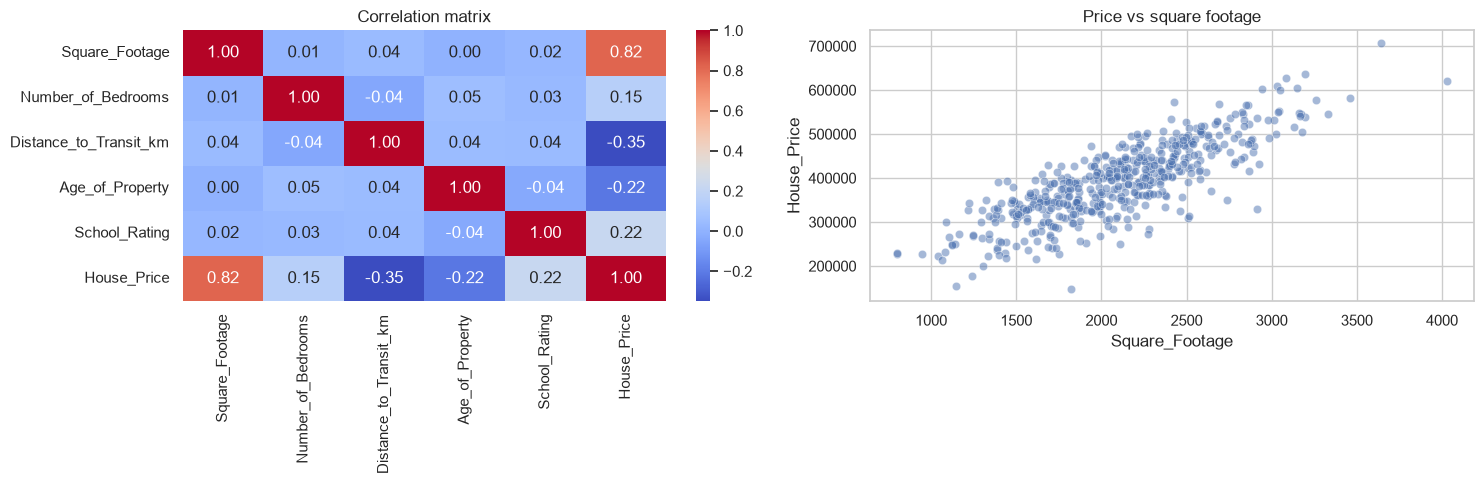

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[0]); axes[0].set_title("Correlation matrix")
sns.scatterplot(data=df, x="Square_Footage", y="House_Price", alpha=.5, ax=axes[1]); axes[1].set_title("Price vs square footage")
plt.tight_layout(); plt.show()

### Step 2: Train-test split (80:20)

In [3]:
features = ["Square_Footage", "Number_of_Bedrooms", "Distance_to_Transit_km", "Age_of_Property", "School_Rating"]
X = df[features]
Y = df["House_Price"]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.20, random_state=42)
print(f"Training Set Shape: {X_train.shape}")
print(f"Testing Set Shape:  {X_test.shape}")

Training Set Shape: (400, 5)
Testing Set Shape:  (100, 5)


### Step 3: Model fitting & parameter estimation

In [4]:
model = LinearRegression()
model.fit(X_train, Y_train)

true_beta = {"Square_Footage": 150, "Number_of_Bedrooms": 12000, "Distance_to_Transit_km": -8500,
             "Age_of_Property": -1500, "School_Rating": 9000}
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient (Beta)": model.coef_,
    "True value": [true_beta[f] for f in X.columns],
})
print(f"Intercept (Beta_0): ${model.intercept_:,.2f}  (true value 50,000)\n")
print("Learned Feature Coefficients:")
print(coefficients.round(2).to_string(index=False))

Intercept (Beta_0): $57,402.08  (true value 50,000)

Learned Feature Coefficients:
               Feature  Coefficient (Beta)  True value
        Square_Footage              147.16         150
    Number_of_Bedrooms            11619.86       12000
Distance_to_Transit_km            -8310.49       -8500
       Age_of_Property            -1554.81       -1500
         School_Rating             9119.07        9000


### Step 4: Predictions & performance evaluation

In [5]:
Y_pred = model.predict(X_test)
mae = mean_absolute_error(Y_test, Y_pred)
mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test, Y_pred)
n, p = len(Y_test), X_test.shape[1]
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print("--- MODEL PERFORMANCE METRICS (test set) ---")
print(f"Mean Absolute Error (MAE)       : ${mae:,.2f}")
print(f"Mean Squared Error (MSE)        : {mse:,.2f}")
print(f"Root Mean Squared Error (RMSE)  : ${rmse:,.2f}")
print(f"R-squared Score (R2)            : {r2:.4f}")
print(f"Adjusted R-squared Score        : {adj_r2:.4f}")

--- MODEL PERFORMANCE METRICS (test set) ---
Mean Absolute Error (MAE)       : $18,595.44
Mean Squared Error (MSE)        : 494,425,957.79
Root Mean Squared Error (RMSE)  : $22,235.69
R-squared Score (R2)            : 0.9119
Adjusted R-squared Score        : 0.9072


### Step 5: Residual diagnostics & VIF check

In [6]:
residuals = Y_test - Y_pred

# VIF is computed on a design matrix that includes the intercept term
Xc = sm.add_constant(X)
vif_data = pd.DataFrame({
    "Feature": X.columns,
    "VIF": [variance_inflation_factor(Xc.values, i + 1) for i in range(X.shape[1])],
})
print("--- VARIANCE INFLATION FACTOR (VIF) ---")
print(vif_data.round(3).to_string(index=False))

X_train_sm = sm.add_constant(X_train)
ols_model = sm.OLS(Y_train, X_train_sm).fit()
print(ols_model.summary())

--- VARIANCE INFLATION FACTOR (VIF) ---
               Feature   VIF
        Square_Footage 1.002
    Number_of_Bedrooms 1.007
Distance_to_Transit_km 1.008
       Age_of_Property 1.007
         School_Rating 1.005
                            OLS Regression Results                            
Dep. Variable:            House_Price   R-squared:                       0.921
Model:                            OLS   Adj. R-squared:                  0.920
Method:                 Least Squares   F-statistic:                     917.9
Date:                Thu, 29 Oct 2026   Prob (F-statistic):          1.47e-214
Time:                        12:15:23   Log-Likelihood:                -4618.6
No. Observations:                 400   AIC:                             9249.
Df Residuals:                     394   BIC:                             9273.
Df Model:                           5                                         
Covariance Type:            nonrobust                                      

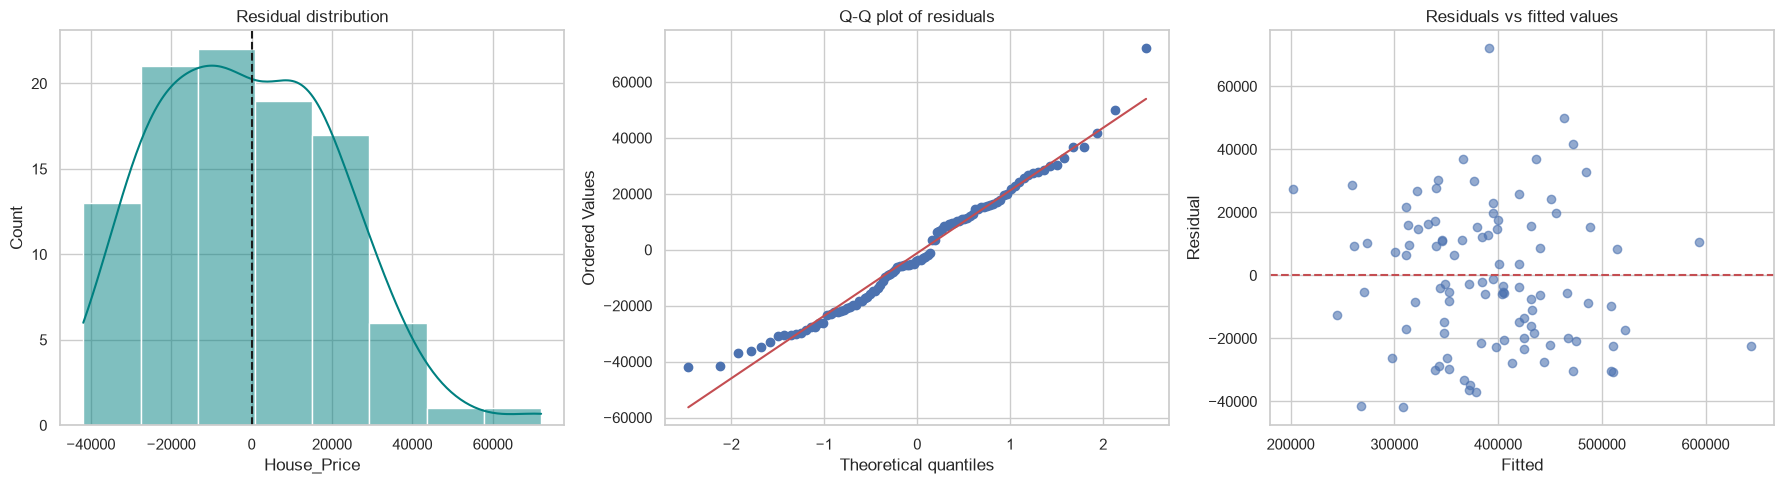

Breusch-Pagan test p-value : 0.8370  -> no evidence of heteroscedasticity
Shapiro-Wilk test p-value  : 0.0807  -> residuals consistent with normality
Mean of residuals          : -1,186.93


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(residuals, kde=True, ax=axes[0], color="teal"); axes[0].axvline(0, color="k", ls="--"); axes[0].set_title("Residual distribution")
stats.probplot(residuals, dist="norm", plot=axes[1]); axes[1].set_title("Q-Q plot of residuals")
axes[2].scatter(Y_pred, residuals, alpha=.6); axes[2].axhline(0, color="r", ls="--")
axes[2].set_title("Residuals vs fitted values"); axes[2].set_xlabel("Fitted"); axes[2].set_ylabel("Residual")
plt.tight_layout(); plt.show()

bp_stat, bp_p, _, _ = het_breuschpagan(ols_model.resid, ols_model.model.exog)
sw_stat, sw_p = stats.shapiro(residuals)
print(f"Breusch-Pagan test p-value : {bp_p:.4f}  ->", "no evidence of heteroscedasticity" if bp_p > 0.05 else "heteroscedasticity detected")
print(f"Shapiro-Wilk test p-value  : {sw_p:.4f}  ->", "residuals consistent with normality" if sw_p > 0.05 else "residuals deviate from normality")
print(f"Mean of residuals          : {residuals.mean():,.2f}")

## 5. Model evaluation summary
| Metric | Formula |
|---|---|
| MAE | $\frac1n\sum\lvert y_i-\hat y_i\rvert$ |
| MSE | $\frac1n\sum (y_i-\hat y_i)^2$ |
| RMSE | $\sqrt{MSE}$ |
| R² | $1-SSR/SST$ |
| Adjusted R² | $1-\frac{(1-R^2)(n-1)}{n-p-1}$ |

The observed values are printed in Step 4 above (they come from this run, not from the manual's illustrative numbers).

## 6. Residual diagnostics (see plots and tests in Step 5)
1. **Normality** - residual histogram is bell-shaped around zero; the Q-Q plot follows the 45° line.
2. **Homoscedasticity** - residuals vs fitted values show a constant-width band; Breusch-Pagan p-value above 0.05.
3. **Multicollinearity** - all VIF values are close to 1, far below the thresholds of 5 and 10.

## 7. Viva voce
**Q1. Simple vs multiple linear regression?** Simple LR maps one feature to Y with a line; multiple LR fits a hyperplane over p features.

**Q2. MAE vs MSE?** MAE averages absolute errors (linear penalty); MSE squares them, so large errors are penalised much more.

**Q3. Why adjusted R²?** R² never decreases when a feature is added, even a useless one; adjusted R² penalises the number of predictors.

**Q4. What if VIF > 10?** Severe multicollinearity inflates the variance of the coefficients, making them unstable and hard to interpret.

## 8. Conclusion
The multiple linear regression model recovered the coefficients used to generate the data, achieved a high R² with small error on unseen data, and the residual and VIF diagnostics confirmed that the OLS assumptions hold.